# Stock Market Sector Predictor

**CheckIn C | Matthew Hubler | November 19, 2026**

This notebook tests whether the 10 industry portfolios with stronger past returns are more likely to beat the broad U.S. market in a later month. The portfolios are *industry proxies*, not the standard 11 stock market sectors. Each return is a monthly decimal; 0.01 means 1%.

The primary rule was set in CheckIns A and B: at each month end, rank the 10 industries by their **previous six months of compounded returns**, select the top three and compare their following-month results with the other seven. January 2010 to December 2021 is the development period. January 2022 to December 2025 is the held-out evaluation period. The 2021 observations remain available for the January 2022 lookback. Secondary variants on the held-out period are exploratory and are not used to revise the primary rule.

The embedded CSV is a fixed extract of the cleaned CheckIn A workbook and the CheckIn B Access query exports. It makes the notebook runnable on its own in Jupyter or Google Colab. The original data came from Kenneth R. French's 10 Industry Portfolios and Fama/French 3 Factors files, retrieved November 4, 2026. Market return equals Mkt-RF plus RF. Industry excess return equals industry return minus market return. No transaction costs are included.

**Run:** In Jupyter or Colab, choose *Run all*. Requires pandas, numpy, matplotlib, scipy and scikit-learn. The hidden data cell below contains the fixed public-data extract; expand it to inspect the full embedded snapshot.


In [1]:
import base64, gzip, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

DATA_B64 = (
    "H4sIAAAAAAACA5Wd284mt5Wez3MVvgA7KJLFTZ1mEmBy4AmQTI4DjdwZC7FaE20CzN2nW3L/vdbHl+/zyzBaaKCfIou1PnJxbf/8"
    "w8ef//rH//rxL7/89POP//6//uGHv3z4+rd/+ub78Lf//uHnX378+Mc/f/Pj//nw89//9h/qVa4/XeXT///4n3/58V/+9sd/+OHj"
    "T798/+HHP/zllx+/+Ze/ffjpj3+6/uN13ddv//v1b6313/4W8f/y8cd//fdPf374/J/P/+penZh//O6fP3z7x//0y0/fffzw009/"
    "+PB/f/nu377/8PHnX4m5CvJ/+/Ty//jhm0//+cO33/z44be5Xsj9+ZuPv/zv3/785ttP6/Ddx3/9+z9G9J9++LROX1fp4w8f00JV"
    "Xqj/9vNfP/z4259/+O63j/Pdl2Xujej/8dcf/u2n3/78wzcf//KHnz78+P+++/bvfFnI//OHv337/ec/P3z7w/ff//Lxu2+/+fm7"
    "T2/zKzHmJP5//vzd33769c/vfv4y7ft2X7o64fr8ndvzd/pX+NnhJFqfF7kTcRSsz7OdSL+K1edP0xZQSqg+/dteC4BGpD6/7BjA"
    "HwTq8z8fNPZRnD4vVKWFOgrT53lPmrcSpU+DnqkGkvTEbzS+/JYj/CpJrV5AOEkag8ZTktRGA+ogSaPTZL0k9UX8WZK+7MVn1knS"
    "qB1oJ0kTF+xVkj6vcqln6KYtqc6v8BcRSfCrIN3XAsIJUsXx5ElXCw16kKSGIBxz5arwgLMolVWAdaJUO43sRKndNLYQpbr6Geqk"
    "Oj1XPFPnenb8VXX6tLqNGK86ve29Z14J1HqT4iN3Up3WjVMGmeoTn2BUpzU70VZ16nch3qpOfeH46rz7srVpbIBwlWvED9Z73/FN"
    "Lx91EGOFa5SOvBKuMnDck3B9PbmOKG1YT6EnGOH6evIeaStcT8HRrXC1dRMvlanphp3+ECw9aVNP2+HXQ3COBwh3CM46iBbaVC03"
    "UIcz8InHkAS9NjUbTfd8BI5JS2v18kEzd0fg0+kjiSNwuMVaeAT2uEvdXy6ZEd92qXbfxPhdKl2lNS93qXkRd9yl+iSUdqmCTzC7"
    "1Cw4dbtLtQdHt7tUeR7ihWhdbRjqgU2qRb376WOHXzepJ175JGE2qVJ7J1psUs9FY+pNqnw6NAH0m9TXs/rEmytfL8CaTapUHNle"
    "+RZ9VnXlG+chf7VfuSvf6uEcaV+Gj/B25esLCGs7iDcRTQtBKg/N8mSFKhNAL0j3fQF/FqR6NWDthQ8XygnS3QfQQpDKMlBBc2a4"
    "oF7j2uFXQerxhyYJe9JdsxGuDrrWbsAOolTuBSCcctc14QFnWbruB1irORWauj/gFg2utPASFcVXiozjX0b8TfFabYe38y3+XiTh"
    "tqX+LKLFttTvDtTJpPk8AMK21Gjgsyg9tQHrRKlVWma3LY1O763Ot+OEy3tceDX83t9UtUi/StKbnn8knCS1pxItvXeTsJNN8yoA"
    "kuuuTXiAOeKieVyyVvO+4oEjcSdM19WBVkbNuBW+QpWEKWl37Rb0bhtoQFgDeVICJK08LY3GPMnSTSBsS1GIJW9E6aGltdpSNKJI"
    "2qrdSctTtJKk27wsuezKirrAPXZ4c/6WAoTVlkr8tBpXVqa4rJI6KUvrBtBLUrtousYgUOKuJGEnSkw7USrRNyppZQuIZ8YrRE67"
    "Go1qX1zXCX4VpdKJsAdc9DBqWkhScoVK6iBJ9SkAwp40iDcuu2sAa7XuTiNbl12lsYUg3dHg8gqhy64le2Wpc8f3aKdeiPH7UnLZ"
    "aV4aBB7CTubKmoyNEoXIlOumB5jNqQ6knVBdC7+R1ZkmvrwyDLzd7RVF3rpPP6P0sb6cthHf5KqmkDTJWLmq90Be2sHXJO4kWG93"
    "3DOK4QU4uJOsgksG2vgi3psJGvLSW9dug02OM4gOjxqD8MrBX/fVmHJEvOWp45Da9DQmcSfZupMnWKJkfborPcHI1lcb85H2spV2"
    "Pclb2bqfRbyWLfelyIFXaopH6Y/At43ryR53xXgHXtqhNS+Fq+BcT8I1yiCUhGvgE1wMC49vhaumjUvyPoYlHeiSV0p7vQz1kGy1"
    "HDjT145v8VFZHiVjZeueC3kpW8lDKrmDbJWvEXNHFGTrXjj4WbZK1j0k7Z3DC3kvWxPfXxrPRzlj5NT7JCVfrQultLbDL0diidcz"
    "TTjvcAkRtgdaWc9DSKOmDt7hu9DrgXe40XSPV8LSwt1Zs057fyYtsw8ILkCrEJZpXhat5ysF2l1Z89duvZri5CTib4QPDilvhCmi"
    "UGInW1XDAb08lRSzIx/g1PYLaWuuSncGidsLIS+buhCmXKNXqvKFMFr3Zt/pTa26osdLIr/D/ClxZUi/J1DHu2BMtpEkiNQi3lit"
    "cNbWwBA9r5K2VqtoHJS0sqRHE1+CKjj4Pm/IMU+oXwLezJ/RYyYJZ/5ccXU1LSWpAXXyFEfrrgS9IF0xy0zyZ0GalSZtzZ8XfRib"
    "RtVomZXaVKf5tBRz0KMH6v5yXY7w5imOSRmS8GlUjWh1zlWa5cm5F7cUCYJL5qHpniXpjsGHkrUxB4WW2UlSj2E3kpYWTzNhdO6l"
    "nMki4D3sN2ZCScSmdsYIQE2rPekh6iBJV/JpK5Ak6QLeSFI8KyTrQ8gH0H5Pou+qJOk20E2a0szq2eo7vslSSfHYkvGm84Jjykzh"
    "gdhZW+qEwimXcublA5y/OF9yFO01Jpy99xg/hCuxmm610dU3VzRLvBkAI75n5yW5kgwUNriQl9anehN3EqxcS0GiFB018KVdasLE"
    "ZfbWp+TckLy1PmV3n+Sl2TwZVF8x9Pf1FEYUc/uqcvf9aiVbQNgoqYfGkxEJ6wbqZC8oNFk4/m4a+L3Hn2JtlFSOhhe0NT/F5GdJ"
    "q+DN20Do3Hu59Qt6sz6tAoR37aXgH4krnXw0oE6a1EMgWZ5ouu7YqzS4tTvVCrTNT4gJPpJWstTN2y5Qyu8UgNT7Dm+iFAPYJWF1"
    "8lh1QtNKiXomUKfbHb4eaFApqkvxptxKacDaTWnSMlv7JS6YOuDabcaE3Lu3eIXf4BivUA+5dy2VflCEk6RSkRaSdMdAREmdjrdJ"
    "rweSFHO1JG8kaTVg7ZYUwyglbbekGIwuaRlOfv42mHs3XmKc+k7vl7s1iPHhBS/RNoqXcVFPJe69cVECpbiosegJJnXqaQT74mIX"
    "8lYHrzfy0sPyGIqS8Wo/H69Fl60rKcNMIXaPSslxklZ6Uy9AnYKCZwcQVPB6Ae+q1TV6V7tJZe+MoH3OC31YedxN822xTt2IOT5F"
    "wJuDJeafSMKJ0pXykSQtE6g6DXqUJRqPTAQxUls+wFWqI9bvTVFrk7i1PMVsJkmrsKfjkA2ddVeLKvVb3YgIb/lTyd2mCGsZSN4v"
    "SYttacXiCpI6OeuuG0CoVBfXVvKutgotrduVeqeZe9WpAy0EqV8GwhCClP1d6trpLeo3KsSSsLsS0zIohWZ5UsIrDQcHXLT0SN7F"
    "D1zA+gSFG2jrYom1NyWtlPBqJkzOujta4+7r3uHNLpAcioqwW1K8XmlaGSuTp1lRp9Mtpj9JELakqHBI3hgrywOs9dXFX7ikrdd3"
    "0GdVW9IwE6Y8vBbvvSWWYWlHT108niTiFaVFtErp7DTmyVaZdlwFwpY0aX3MHW7R2N7CVIG2h1sjWklSMRPuENJ0RTXiy3aW4M3A"
    "FAPqJGFNlfG2qGlp9C5AHbPMF4CocD/wgLMk9YfW1qeZ0zr7DKlJC61ub7OYKQ8uYd9T7p7ARfLdQ4yPIMjGIslLI1POIFPcycj0"
    "mhAqUDBb5tw79QDrS7mI9vlR2cikeHuTe3Dh1FVuuc80qep4CqMcfYc3L290nErCluiJipOm5V1uAnW6y1V6PcgSjuF2kjebVIzn"
    "kqy9yz20UL5UdANa5Z1382XX+8PBUwxnxHfV6bmI8Y7eWpB/Rw6n4o5b1MIh4eBrDz7B5nAuou0edacCypL31XzrQ7zusuGkg5x1"
    "I5boanPu8Ga9jB5FSdjqGKsSrZx1hcZ8V31DBVItgwv4dzrrJGuvd9HfIGmrlEf7iKSlT+UsC+isu6Lu9va9IrwVyoxWd0lYQcLx"
    "ZExvrNMqqYMg3dHKL0EosxLlXvLvFCTJ2uOu0MjWTrBowVQgSqwh+QoVLP2UAoLLDm+WyzWBsIKUugZJWu1I/QLqWK+HJgshTZV4"
    "Y3CaNGmbZjBoobxnjj6rzPNd5UyRZ67UdDEUMNgJBOFLGy6iVUhTf4A6dmu5AISzLbqOJO9Cmjqw1gZeibYaOC6zjAc/rfL9jiKZ"
    "bdTUyazu+N5PI2XGSwZSMi/kldlp4rDHIip1EYq9WnCdjAJ+t0a0VcDHjfOHdhqFeFnn0C04FvKNVoK39JsIb1aCZIRXhLUSxB+u"
    "ppV7pRF10r9jeLMEKRZ8AG/2qJsmbdWm6JqUtPXTdZq3Upsu82UbWglKKgnZdnpz1N1EeBPBKITL7mQpwEdhJwdLo/EoqKkD72rV"
    "38B682U84yVuVadCE1fbUi60mSHy1eW6UFdZO71vS5MQf9xdHXkZ18RTPcnTQpKyCx56gDOJPzfRXqYenL4vbIGTV1tULj7yQnUS"
    "q3h01Zh+fh8cd9daQFiF/K5EKw0q9/UT1DEoZQIIG1Qj3gSlTFoon6JJH8YnqxSglXPlMtDAoJT4iWLvhPuQQXen/A1F2KCUFPsu"
    "aRVKEO0Skjq20igAko3gAt6cdDHeR7I+64kWyrrpOo2tQgmiFvMKYQbdnXrhvbWkifhejKAPYmxcSioApXF90t3EHW92qfihRKnK"
    "XMNJuxpOFVfMVzBMVfIkb8+6XB1U4bIJ5+0wSqjLdTXqvcN7Ql0FwkapRGuXpmWROaJOBvFklFYgBM6lG5LiXeBcAdbe7C6ivd5E"
    "7632qGaGfLCEbw77eMaOb3vUTMqtZH6H9UnzcpOqlbhj4fGOQ767g9TxCbYtQiHaJxs0XHIf/ZQjkRQvk1ecdKDbrkU3Y+1lh/eS"
    "9oUQmwmVmitIWm1TKXVRUSd3S1KlFAhG8kEv6wxQNLaPyiTaqlLtAlrWwjRDFtTJ0ycaO7zXgu4TEH/gLaJlfC9N8yRJOBw1/3mA"
    "N0p5apWhWCdJE2lrysy54IKWxZ8NVNH6lExB+W6oHXdXvwnxx11SUDUvj7tsQ1LcMe33WoRSnG/qTS+fYAwGBYe3F71czUrhPuv3"
    "wm9sO3BuVH+HG+/FwVWuHd9Pu5SELhkrWS012tC8TP3FqZ4Eq6VqYRIlParjnI0ela9NkvaGTeZ9L4R7Eq9EK1XReqXYjRdOlVHa"
    "Du/RT0TYKqsVaRW0EqPZJHUK9o0eCAlS4mYD3lVZvYG1l70xgXZn33pomWVEZszifaXQj3flLlMx5qWfymNmH7RkfEJC7lIleRW6"
    "kottKOx42Uv7v0Tx9Kv0BFekYOAbW4P5wDf3x1/Byet+LW7WNycFRw9qf3Z6q+AbI+0l4ate3ETLNJdOg54LZQ4g31sn88SbHLxR"
    "gQUT5wO4jYlKFdYULZX0dYbQlxddRqXNHd52qR7NdhKxwpTaDktaHXk4zaN3eAEIPpgYICp558yrwL6v48GJfrd9U9JyY7oNxQ3w"
    "Uq+f0uuO706YiYzXy/uDvDry2iTsnSl4CqU6T6mxmnyC2Z8uhKFFWSHe11rt+MGUZPXqFhz9ezVa3kufO71J1op1vyViXcWVBtR5"
    "CRdQZ0WKxgOz1DOAN/vUqsD6xIQbaO8rprFlUJT5tJiH11Pwy7jqju/bVGoMKBm7TfVkYNK80qFWw7meJKqnH7pEyVmcKqTLJzj7"
    "QWpAK2m7UfWGo9uN6h1LJ299l8PQydeS96ddY8d3hWoi462eqW+t5pVwjQe5c4z5TejvM06pJ7gkzwtpUNOR9xe/5OSUvNSvHMaF"
    "NOMeP2ff4dd+d6kStiRcv7tUA03T4gxMbgpJHVT15yYQ+t3FUsSSN2XFOi2UTfJctFDuCHwuGlsdgfGe+Qphbt6T7tdzh/dmUkTY"
    "O1+KfJa0zKhaQJ3ufHcBkPamp8IDjDLVaNb20pcKsyvaxx7gxHWZaENhibp8YNZy7/juMU5uJ8mAobMiL299iJ2jWm5CwSY1cZlc"
    "5F2ux6Boa+e8cPb+uHsG8bJPWQpOT9hgP1+pKRKnz7bjws83ifGKenpTzQtdKpyVR+6oqKfYVYlSUXt8Z9eWeuIq+3oZHfn3JzBI"
    "XFViGe6Vyc13p6rT13Xv9O6bye2PFOPTrNZCXoYmpKbUkjslFuemWooEueq4TM41kxw7krZbVimE+4YJiMv0YjfnRgXtolliPHOH"
    "X/XzK1ZPkoTv0Yk09cOT1Ml7HJvySPB3mKgkb7zHhSbty/7SyE6URiFaSNKM9WFfIcrbSwkUbwliEX7Vz5940ZOE3ZxS40qNS6fM"
    "AOoYg/cACBtTpbd1iTEFWEgB7YDbXWnQi+s+ZebrdC47Fl1nsSr+OHn4Up6rRHxu+k20CuiMlxBJHb3FqSS+Ikkzp/ma216qyaxY"
    "n683gPb5xBNoWUTavOw7Wt5lJabs+JYN0zsh3rg5b+Sl3lQmccduZYVIChHGKVvTJk7cytRshNsIBP5c6rS73aBUYnNFQ0+LmQ/j"
    "5NyrsUqzRNwONTvSqnpG1AMkdcqxigY+CWJCDI1sshdwpWyxqNQ9UtG+zH0HWh531bwtpeulmkRXLzu8mTZT/QtFWNNm6jkjaVlf"
    "s9A0jznFF4AkS/i6RpYqvSxkVg3AfV2fpOMqXDcFWmcK3XlZE6/PTvvOnIrwYQeVaNuT+kSdsxdoPAzfXPAAl6qHo0MoC+FWfUoF"
    "bBQtMxfaEfL+uz/FYpw5kCjiwu40iPH6Uw5RlbzaoWYOUlLc2VbeCaVNqix6gomQ4lX2Bk1eMb9PXfj68tgb7kOTS2+miqhr7vBm"
    "MoiXPEnY6gfx0qRpdclrNOaxTDmBVFM6FvGQDzgKVEkxoJK1zuEYnitpa3zqtM7S8TKMNFTs8BJDZte9w7aWtCSsKEWnpablmfcA"
    "dfQOE/g7atlJ3hifHmL9gRezgSXu25fRi6tKUVFdTNDkPng19Qp61g7v/rvUGUshNpc4NXGUtNqVohoiqaOHhd4PgssHvex7+r2e"
    "WB9nUIC2RoJGY9tWrwLCXOIYSt9ijsM8Ouzi71Qivq/5TbQyEaSq0Io6mQgKgdR1qgPvLAS0tra+QarzrWgfTl5ocLUpLfO2DS0E"
    "6Up37fDehSO5RxRi73SlEK3Ot4umeTrfUgFRBVLy1ALe3ejylUzA3nb5AO3LQ9HEVfJUMxD66dL+HTNE56kXXjJcSsSKUu9EK1F6"
    "aMyTsWlNACmAoABvzrdGa2t3pUEL5T0rNG8pSfUMoZfuKh3oPSchNUZUiD3g3Dt2UxhqAvaeqpoSpLK/tLw2FuUC2BfJoKn7oMxO"
    "M5flyO8zNLD/dLQur77Du8s3Om0l4gMyY8cFjcuqdUQdhakCSCl4hR5gytbFnUmy3gqejimF+1DMqNZKXDbgiLE7r9TkEIJ0WxD0"
    "3jy4A2EL/g4ajy0CijqFoyRHugJ/j39OPsC1ob6B9S04LqBtV6B8jxO02pkes8zonkv7RJ07LNLNCbGidF1EU/dgSR2L29NkaWOK"
    "Fzn5AHfM9Qmw35kGrRXsTAtwJU3FQNT1rrdUi23t8BZwmfriKsJaKsdFtDQvLaBO5iWcLO1LjUY2p1wu6idYq3/f9GVAZaKF1odc"
    "P1KYXFdihnltfYe3YnWp8ZIinCyNaI3VtGy7kXouKex0yKWmzAqkxsELeGP2juqaZP1djlbKylLvNHHZw8XMuHAz6thiLRsVtDMu"
    "HaqSsEEoKT5I0jLicgF17Gw+AYT4uIt4Y6yMziLJ2hKak0a2DpSoBktaXuTMhCuXekp3x77TWwOX6wLCp6mURbiOthyAvaccqwSp"
    "s2sB3qVq0qTtttRvoK0sJS+komVxgue0Wusd3riZ2m0/O7ztSnMCYaMsY4iApmWPsgeoY5QlgeCMexrwppP5U4B1kvS0BbR1xhX6"
    "rDJCYJkZ47Y0Uj5p623HX+9xJSfASsbvTFdBXoZa5sZ+ijtWuUi1liQKGvhIdfTlE1woeEPaRzLduORWdZopkknycpfqTjqwcmbv"
    "Kde5Cnxv+IqIryKWG6tIXmrjOcFZcccguVRBRaJkKsiJ9+oJNqO8E+0rqHQcHSqo4JIrvby4D82VM2MAzVuZiEhvUXJPAwLUqUG4"
    "VKeuDtixanSq5aBICpR7aGjjs8v9EQVrcw1SpLaivUDlvpICV9q5G5NqZ7bUMG1dO7ztU8lgpQhvMriIljGXC6iTat5pOCzxRCM7"
    "s3gH1prFF9He/NTow8oyrPMMDWypGIV3tB3eWyVcQPiN6aYBZTn7FDOvqGOiQby5SBJsBsmwrnhnF4+GVAnbi95DQ/sAXlpotS11"
    "s87srkuJam3s9BbAG3cySbw7KkXTshcQjXlqRh2tiRIEk0GMapG8i5W7gbUnXLShStpm06VMPkWrqMthhlxcxD6+7ig7vQc4LUKs"
    "zSBeZjWtChHEvVBSx20p9mqVJAYSDHiAK0VA07a2zGQyVrQVpkW0OuLiTvgKcWnMVPygCnpXlyYQYDHohJO7TlLHoBQajuoQFOBd"
    "4GVSBxRs9aVOU7c1fCd9WF0L8/xxOZWupirc8x47vlmgSkqNl4yVp7Uq8rKI78S5nvanh1FSwitO2hXxnYNoayVYqWWr5H14eOqN"
    "JXkpW5ebNhnKe6qRsZ4d3k+9FIejEJ+k2RfhylR+F6BOpvJBw8FOlVOoBG8OvUWL633BRNtDL0ViKlqZnOo4Q2QpL7kB2JMVMF0d"
    "s+TixpLx+1T6yWte7lPJJCm50z71RaU2qN+nSkk9ceQTzvtUuRa+st2nngtH98XG+f2lpTylKifsQYfepztbUMdWjHd5tEOvXDFh"
    "TRJOOX+i9VTT6p4XjSmSOtWDHgNAv0vNmEoo+fMu9UxaKLdLrZgKIGkblRlNX5KWranXGcKM33SrHdcOb57hFAKiCFshbAyiVeHC"
    "dgF1NBgQCJ7hRstjDAbpyq9Yb8ekmVvP8EXzVsddMua8QOy7S9EnsT7Gc3Dd5eRbRdjw3hjVpmlZWbwAdbQXpHZSioQslpRKonh3"
    "x2v0stb4lBKqFO0rF9KHVbKU4stfoBtbmoePdJe1w5tJPBoGJWE3pUXjHSo5DcCO8So3gCBKMS5e8qbdQRRDydqKFoPW2R5v0RMg"
    "aZk8fp2hjoXEk2L71h494ruxINVrloxXwjuOeQhXuYg7Ggtyxx2FgrGgj0pPsB1/kLZK+EjhJpKHwju4dDJsvLthwXP36doSe3+U"
    "ucOv29SKNaQkYYs+x4BHTStTwaJZnpTwqDtJkIo+03RdU5YHWGsfT71vFG13qeiIkLQslnKfIaqCeUWxKHfd4d3qlKwhCvFZdkjL"
    "mKcU6quwY13VCSBVS7mAd604aWzfirMCba1OKRdS0XJXSoHNLxQ67r5a+FKYWsT3hompe7RkoCnLg7wMdho3ccdenPya5L9LXQrk"
    "E8yJd49GtO9xgINbnbzigqtNKnWoe6UeNBXEC1AX8ObES2m5irCpLRVp3TWDpnnKbUnmaQXCJrVoYLNJPQVYbytoQFsfXrJyK1qJ"
    "0nNeLEy4mynFqtYd3s+7lIOmEHveVaRVbEG0VUnqdNxdBP6ehDvFO6vTA6yVpHg7lLQ97gqNLY+7ZiiuMxdDiZ5nh/eApwqENRXU"
    "SbQyhKd8O0Wd9qRcEFuAEPCE0zWZLVcH1rrrCn0YK0k3zVtmtpT7TJElvMeQnDexivCrJI3oLJaE3ZMW0soSnoJjFXUKUWk0HNW+"
    "XMAbx2+0XkrWquCNXtmebhe9t+oxFveICNWLk+1GKvAeugi/wcLiNAGxktSQVopSiVFkEjsmsESnkSQpMuVu8ABrC6fRfeMVWiyf"
    "apCqBylcidMyr4sZd7NGrX1dbcc3geqpK4dk7IVupBgrzSuZ6qkHo+SOcQSpablEQapWiliSTzBi9SycujdhpgZykreSlfMFJa/O"
    "vGe5L0Veu5q6i5ZW+46/Cle7b2SscD2TeSlcsXej5g7CVUZs7KNRCFK5Fk7aBKk88eNq2grX5Pk74SqNxxfCVVI9+w0DN17tIVas"
    "RH/yG/yiUbWYyKUJ17T8DgUiDvSuUZWoUWlKa1SfJGIACEEqkwY2delx0uYMLCsorpq2TcsrfSQVpBKKS2wQZdvN6O/sIcLlDd5T"
    "pAYQNhVh0HjSXFBozFOQSvTQSJDcwRfwptbTINa6g+OlQNK+Kn0BWrb/Nd+GPHZ3FKQaYoPf4L06ZrJOKMSaCyYNqFXzWBlQYqfE"
    "zVSmTIHYfoVGdjnANLiXpQq0V8wH4Up76pehwG1XVoyl7qFBwhu89ziI+RIS8VnAk2i1LzUa8xSmkjZRBfp9qeN0jRkz7Q2KtWVV"
    "4v1S0tYBfNF7i31pxFvpKwS1Me8rXsXnaDu8F6aPP1SJOFUp9c/StMwn70Cdevgkh7wCIZTgpoFNKMGktbXxvBfN3EpS3I4lLc2Y"
    "1bwt5to9uUCPwjdzwZ2u+5KxN7pecczDOdeIO4ZjFhyS+telIiryCa6IytOJtje6tgbxvlDBM4mX6VG5rlDG3tHGLtmi6jV3fD/z"
    "7kEMtAFeyCvhupMtSnJH4Zo4ZRKulBUin+BMnEz7Cj3jId6H0y3klWp+uwUHs/lbjPKvN8QXVUx68uoKNeQ1YY/AUF/xQIsj8Fk0"
    "5sFa0EL/Lw3aI7DEdp2aP1sLeohM0KxPaaEPY47AcgdPnqZVEYxhFgsceSWVhr7HvcNb4cxBhL3jRW+9ppVWHlO+JXWszVMB/B1h"
    "mZI3LuEUPK5Y78ijhfJhmfTeqmzBOEHlHUl2Ly3v507vJVg7IbbKeB+IS6dwJezoymuIwkl3F3xlp0ZNHN/3RbxwxfxJ13H2Uo26"
    "b4OhS2+lAJ9Vdvr1rGvJvKEIG0qXHPCSlup5qjiusJNFM3Z3kSCl3dHbuvzNB1johEBLZU2alWhdNdNMGZvapZpGZe7wlncXo+Ek"
    "YfcoHO9Q1/AB7CBLMx6UEqRcYHpbc96l8CvFuvMuGX8lbQNXBtH7eVeStfoVorS7O0ZA3aG9yxu8uVliXWlJWHNmtPhqWhmhYiNd"
    "SZ0Up2hUlyC4WRpN1wjSpKW1+Swx21/SPhd4AS3jew2ELe1Sd6G35KxI77F0FxC+3lOsaaVxXbu+AnZsqTEBpIrjxJtoOhzb2wZS"
    "eJrCfVmeVNRQ4TLGNxXDfaGoQmaPfoi32LMIb2p40j8UYfeluMCaVhe6mLQsqWMqy0UkOe0WPcBp4MkFpuB3V8iUtJcmfHUpTbeZ"
    "MtbIvFIn9iboPT9qEOKz7S6i1TmX0lEUdYz0bQBC9kEl/r19yCTse9p1oG1SVKOvJHvamQlTT7syU1C0gIXfbgDiu9zfRJMoSeqU"
    "yNI7gFiCjhbInXMXsL4NWQHaKt8xpFrSslxYO0OUXVdTubw3VTzSryWdchcAifgg3+RC07zSmsZViTsddT0VNZQomZs6vrQ77FIG"
    "pKR9W42Go7+zI9mRlwaCFJv8glG6XbviLjWiy6/o/nYlFTSXhK1TEEMTNK02qfjrkdQpTCUGT0gQ7nWTpuuqqdDSWgMBLpQVprsS"
    "LgMxyxnCbLtk3i4x+q6c6mP2VNVEMtZ0eeOQ2vtbB3FH72/ynkqUOmmk36t8gtmkevI7SNq6WW4c3Lf+Kfj6ugWnG7Zy2YLUyPDe"
    "6b3zTwfCytWYRKtiKn0BdYzxLQD6TWpdNF0T4xtztSVrxalXoK3x6aGPJPao1U+yUMFr92umRionOsrY8dfzbiYHmkR8xacUx6R5"
    "XR56EnfUpNZNKOnmqQ2UfIJrUJb2V0lDeWhcMoh/Ql6nCF8G41y8l25ja8e3mk9tEGJl6+4Veem8S3VtJXc0SNVGKPb/wXWy4U/4"
    "yt6H1zvxv6O4isJ12R6HNYpaiTb+N5N9hLf+ZNHRKYl3l8TQtCpkkJp0KOpYAaoCSHXHaWBTXOWihfIWTloon5dw04uLA/AZZsbU"
    "6q6MJ1WkDq3N3vDdLFUXMW6XKl8TT868tCU8hbjjCZh+phKl4hiDHuDyhZP1RNK+7vjEFbcpnTlWSPJql2rTLXj/fdHlb6pWxF+V"
    "q9zUUyK+uFjaVzWvKv0+gzBuDXREqbZYqg4mn2DyqFIpTgl7I1XScSTvjr+vzo4jLmscuEEHNktI6uxq945vWQsjHfOS8Vp7av2q"
    "eVkGMdk/JXes03rjlNG08NAT3KaVfhSS9nnoE5fMFzkYyKtNa3QnHZCnV+cIusMz+g5v9s/Y5UQSLrI8mRY0reyfk6iDarWiv0+C"
    "EBBciD9vVSvkwGvW5aHf0cMjaXAe08RVnl41y4zFNbP/ovW143sns06Iz61Kh5HmdbWMm7hzJ2F8Szr/VqUnOC9NR9rnVqUDUPJe"
    "Z1+45CrWvBRDYd5ePs2e0nd809qfiozV2kv60JrXpaMqcadKLCVt5RKlMj/pByGfYGRrJdmQtD8B0wkmeV+JJeX9SV5VYimpOtIL"
    "xnl7I4aPr3yhlC7A2u4BhM+JQVocgSs6KiV1SK6qtQDoj8Dnoem6UiwPsLbqQWrLpGiXXJVac0jaVgEWUPldqQv3c+/0VnAzdbtQ"
    "hJWkGImhadl5qgN1Knp/VQCh5kFseSV5EyT8XMDaJi/RHChpX7qVPqvSpZZZZbKl15Vs6W8dICK+5xLndh6KscrUTFnbmpcHXrJI"
    "S+6cYTUIpVzidOTIJzhvMo8Ppcdwyf2Vb+HS6YjhI9Ywda8+cc8Zz9jhLSkmpjJIwvbHi35hTWsfDQ16cidHc7oEyUETt1X5gPM+"
    "NTsNbmuz4EK7E69F17CkpTBVM2PKJ/5aUP5PMUwp0ts+lU3wkvH5DJV5HfXyEHd0+q1OKO1TZdITbGjeTbS3eg4c3e9THZdcVpBq"
    "1WDYNe9KAb2xbFA7lN/MxXMlYssexMramlbGqfsB6uT3azQc1bYj3h19KbtAwVahSgXBFe2tU4VwmXbVzxA6/lK64luh40hvp148"
    "tyRhU0FjAKKmZZ3ECtTRLxPzZCX5O4RJ8saJHPtxStY6kWNig6RtQMJD76365k2zzJ1am8XA/y96eoJ3W1RKDFOIjRnGAXXLvBg1"
    "KLGj97jfQFLDvOjYlw9wh92i0W2aTKeh7c703PSl5EGXipi/UJDCV1N051hjh7eE0Ph9JGGtBrHIiaap4YukTqWAUxi4AiESIV6k"
    "JW+08ZsWyqYWx9qzkrblDgbRKuOqm29DrfLqTP2jBfwqSPMmwiZcxZuDpjGxWGKnhi+xhY4EQZJyp2zBG/tTW8D6I47W2R9xHWgl"
    "SXOeIW6UlxxzJXb5aAdf3kuMu0J8KbvU707zUpxSQKbkzuanRShFHEx8gosTbrhkvsBPe4i3clUG4fpW5zD05dWc5rWuHd/cxDkZ"
    "TyE+mS8n5UleWgxSqUHJnUQrB0NLlJL5Bg7uROsuRFvR6inQSfK+dlTF2eua0/2MoSuvzGxaGmvHd3NUck1LBkpwTuSlcOW+oIo7"
    "9xjC16R9a+DgTkNn2qroN04frAeNeNkrvRqK6t31FIHU6g7vYcPRfSkRZ4uq0UusaeXbizdxSZ0CpWJUtQSpciK97NlLnOLXJfvu"
    "htaSdmfgeGiZZZ6omTD10kvtu3tdO7xVkopvKAlfFqESrZL54iVRUqdy5jHiToJgh+r0si7jmF7VZhwv+jDWSRytWJKWdqjTYt3v"
    "SOabsb7Ml0tVonf7eMxwlojNi2FaVeCMFhlJHd0uqae6IinULnXiVQ9wmTEXsDYztNLI1naQKsUoWqYvXObz0LY0Y5jQW3eqCO85"
    "xg8QtpBUNB5oWlqhGlAnp3AjEIqSDXpZ10eoA+v7dSygfbzmpHVWxoNm3hb9dj2ecK3Ond5rahDhRCm1UNW0ctsVGvNUUyM1LFYg"
    "mKEemq4RpZsmbc1QOa9f0L5WIo0tJGle9xm6uRxZug6WteP7EZfsSJLxOcX55ix5GVOe69Ao7hhTnvK1JUoHXbLJyCeY+9zdceo+"
    "vCBFgEkewgvw/ZXylA1JLxRm66XKP/ecOy2iCzogvvTPRbTSnipRR2t5BRCyilMtWcWbDlWVWF+ebAJtt6lYskjSqqpGqiL7Ag1s"
    "ah3T02vZ4U2SUqFRidgejH0SLYsD0zSPengMvpUkRj/RA1zZRFxeG6nSifa2pkEzlzXJyjhT1DqvxLiTt3y5CO+ulwcIsGB2wlUO"
    "cfR5S+q0Md0EgqkpmuIkbywE8ZYjWR9bQDO3G9OiZZat88yn5ZS81NPzWju970wxelYivplCJ1oZm1I9SkWdyrkOej9K77yAN2fc"
    "Ra/q+70MoG0JzmhdkLTKQo/7yiv0UHfYmBpaS93hTZJaPOMkYi91Dw2oo8ZTOVeFHVsHXQCSurSAd0UNiLUnXOrKoWjbOqgTrQzg"
    "7bzK72iUl9y51yg7vqveHRkIGq/IyyC63MFHcSet6b5wSFKbkotQPsHYL3OlCwX7QlH8law9PNcJUbjsSeXeGDNbZoqeenYYIukE"
    "YV0rTydaRqx0mubRt0LjgREz6i+SN066soC1RkxcKSdLD44tixmYVaa8lpcCceva6b0Qfs6FUYwv5toQl3anhsMeg1QWviUF+qZC"
    "CvIJ5mY3L5y636JSvrjkfTXXB3l1u5vzOO2O6Xc5RSW1IeqH9LuChE9EmEQrlTxuNZI63e5i0KwEQY8aA3hzu2s0ttujxrGZVn+H"
    "yy5VxZe0bLBgJoxJwrksfi1lx7eclhSkKRGrRrVkkNe8dAHjTM+pdzehkHWejMvyAbZnxyDal1uZuGD25Ltx4ZRY5VCnFwr9d0/q"
    "eJ7Si/uh3mZbnRArV09hXgbRlUHcUT3vOCSV3Sz0AOdzaTfRPvW84fR9jWAeX+nn0603NdHrqT7bFf3K/eDO+3QJacRYrSqlymtc"
    "6ui50J/ijtGZKdVXolh9+qInuArBHVfMGjnTFi9x33nhwcnLNPTmPhTl5KVaa+O+d3hTqlLjD0XYTOHoSde0tCaka5DCTje/lIqk"
    "QLj5VeJNzEFMm5GsjarrtM7eZk7fVRbxaWdooM08WhB7vXZ666hXGhC2PEYsGqRp5cy7ClAn/TwFMimQNqdJ62NEKUeyCvbdbask"
    "bUVp0FeSQeNmSOyml/uZxTjhfvDkJW+lJGxmZww007RuZb0AO9nMC80WSyE+8AB3zhWCrTCl4gmK9vktjT6t2piaGZP66a0YSVWr"
    "gF+FKXfdVIS1G8T4D02rAM0Y0SypY2dGGg7ixpM7TvFmW4qno2StwrRomf0JdwEttaXUFf2FAl9eTW2u2hTw7n6JIQISsfEq8YjT"
    "tDziGlDHBsQVQMqOirk38gHGl1fpXcHrQgvtb3WF1oz6Wb9A1EDv079JG2Hb4V2Y0g9GIf6Qu4hW+1I+4wR1FCZ6PxKmFBKhHuAy"
    "7eYDsA0yiKqapH1DxkUzVxaC24yJFTRbtMFe2SCqPXg1nqmS8A0UUrkQie/SVK54LZHUsUxPjHSXJFgzK41sPMJRHCTr+w8voP3O"
    "FGNnJS7t49cZooyWO2XHv5WNi7TYmi5ifJhB7m0heamCd+ROelPqaChJ7JA+6AlGppLTU8L+vMtmH8X7YN9CuIzPrHrR/j9o7uer"
    "WbwBAA=="
)
panel = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(DATA_B64))), parse_dates=["Month"])
panel = panel.sort_values(["Month", "Industry_Code"]).reset_index(drop=True)
assert len(panel) == 1920 and panel[["Month", "Industry_Code"]].drop_duplicates().shape[0] == 1920
assert panel.groupby("Month").size().eq(10).all() and panel["Month"].nunique() == 192
assert panel.groupby("Month")["Market_Return"].nunique().eq(1).all()
assert panel[["Industry_Return", "Market_Return"]].notna().all().all()
panel["Excess"] = panel["Industry_Return"] - panel["Market_Return"]
panel["Beat"] = (panel["Excess"] > 0).astype(int)
print(f"Validated {len(panel):,} records, {panel.Month.nunique()} months and {panel.Industry_Code.nunique()} industries.")
print(f"Development: {(panel.Month < '2022-01-01').sum():,} records; evaluation: {(panel.Month >= '2022-01-01').sum():,} records.")


Validated 1,920 records, 192 months and 10 industries.
Development: 1,440 records; evaluation: 480 records.


## Prepare lagged predictors

Every predictor at month *t* ends in month *t−1*. Industry returns for month *t* are used only as outcomes. The ranking and model features therefore use no future observations. Industry-code order breaks exact momentum ties.


In [2]:
returns = panel.pivot(index="Month", columns="Industry_Code", values="Industry_Return").sort_index()
market = panel.groupby("Month")["Market_Return"].first().sort_index()
features = panel.copy()
for months in [1, 3, 6, 12]:
    lag = (1 + returns).rolling(months).apply(np.prod, raw=True).shift(1) - 1
    features[f"Mom{months}"] = [lag.at[m, c] for m, c in zip(features.Month, features.Industry_Code)]
vol = returns.rolling(6).std().shift(1)
features["Vol6"] = [vol.at[m, c] for m, c in zip(features.Month, features.Industry_Code)]
market_mom3 = (1 + market).rolling(3).apply(np.prod, raw=True).shift(1) - 1
features["MarketMom3"] = features.Month.map(market_mom3)
features["Year"] = features.Month.dt.year
model_rows = features.dropna(subset=["Mom12", "Mom6", "Mom3", "Mom1", "Vol6", "MarketMom3"]).copy()
development = model_rows[model_rows.Year <= 2021].copy()
evaluation = model_rows[model_rows.Year >= 2022].copy()
assert len(evaluation) == 480 and len(development) == 1320
assert evaluation.Month.min() == pd.Timestamp("2022-01-01")
first_code = returns.columns[0]
first_2022_feature = features.loc[
    features.Month.eq("2022-01-01") & features.Industry_Code.eq(first_code), "Mom6"
].iloc[0]
assert np.isclose(first_2022_feature,
                  (1 + returns.loc["2021-07-01":"2021-12-01", first_code]).prod() - 1)
print("Lagged features verified. Model training: 2011–2021 (1,320 rows); evaluation: 2022–2025 (480 rows).")


Lagged features verified. Model training: 2011–2021 (1,320 rows); evaluation: 2022–2025 (480 rows).


## Experiment 1 — Unconditional benchmark

**Question:** How often does an industry beat the market without a selection rule? Compare the development and evaluation periods. This provides a benchmark for later experiments.


In [3]:
for label, subset in [("Development", panel[panel.Month < "2022-01-01"]),
                      ("Evaluation", panel[panel.Month >= "2022-01-01"])]:
    print(f"{label}: industry beat rate {subset.Beat.mean():.1%}; mean industry return {subset.Industry_Return.mean():.2%}; "
          f"mean market return {subset.Market_Return.mean():.2%}; mean excess {subset.Excess.mean():+.2%}.")


Development: industry beat rate 48.5%; mean industry return 1.22%; mean market return 1.28%; mean excess -0.06%.
Evaluation: industry beat rate 46.5%; mean industry return 0.85%; mean market return 0.95%; mean excess -0.10%.


## Experiment 2 — Cross industry rank signal

**Question:** Within each month, does the previous six-month return ranking align with the next month's excess-return ranking? Spearman's rank correlation is calculated separately in every month and averaged by period. A positive value favors momentum.


In [4]:
def monthly_rank_correlation(frame):
    return frame.groupby("Month").apply(
        lambda x: spearmanr(x.Mom6, x.Excess).statistic, include_groups=False
    )
rho_dev = monthly_rank_correlation(development)
rho_eval = monthly_rank_correlation(evaluation)
print(f"Mean monthly rank correlation: development {rho_dev.mean():+.3f} "
      f"({(rho_dev > 0).mean():.1%} positive months); evaluation {rho_eval.mean():+.3f} "
      f"({(rho_eval > 0).mean():.1%} positive months).")


Mean monthly rank correlation: development +0.008 (50.8% positive months); evaluation -0.007 (47.9% positive months).


## Experiment 3 — Primary six-month top-three hit test

**Question:** In the held-out 48 months, do the three industries with the highest trailing six-month return beat the market more often than the other seven? Compare each group within the same month to avoid treating the 480 related observations as independent months.


In [5]:
def select(frame, lookback="Mom6", k=3):
    ranked = frame.sort_values(["Month", lookback, "Industry_Code"],
                               ascending=[True, False, True]).copy()
    ranked["Selected"] = ranked.groupby("Month").cumcount() < k
    return ranked.sort_values(["Month", "Industry_Code"]).reset_index(drop=True)

primary = select(evaluation)
by_month = primary.groupby(["Month", "Selected"]).agg(
    hit=("Beat", "mean"), industry_return=("Industry_Return", "mean"),
    excess=("Excess", "mean")
).unstack("Selected")
selected_hit = by_month[("hit", True)]
other_hit = by_month[("hit", False)]
monthly_hit_gap = selected_hit - other_hit
print(f"Top three: {primary.loc[primary.Selected, 'Beat'].mean():.1%} beat rate "
      f"({primary.loc[primary.Selected, 'Beat'].sum()}/144 industry-months).")
print(f"Other seven: {primary.loc[~primary.Selected, 'Beat'].mean():.1%} beat rate "
      f"({primary.loc[~primary.Selected, 'Beat'].sum()}/336 industry-months).")
print(f"Monthly paired hit-rate difference: {monthly_hit_gap.mean():+.1%}; "
      f"selected group beat the other seven in {(monthly_hit_gap > 0).sum()}/48 months.")


Top three: 45.8% beat rate (66/144 industry-months).
Other seven: 46.7% beat rate (157/336 industry-months).
Monthly paired hit-rate difference: -0.9%; selected group beat the other seven in 25/48 months.


## Experiment 4 — Equal-weight return comparison

**Question:** What happens to a hypothetical monthly rebalanced equal-weight basket of the selected three compared with the market and an equal-weight basket of all ten industries? These are historical gross returns, before fees or trading costs. Growth starts at 1 in December 2021.


          mean monthly compound 48 months
Top three        1.19%             61.73%
All ten          0.85%             43.05%
Market           0.95%             49.09%
Top-three mean monthly excess over market: +0.24%.


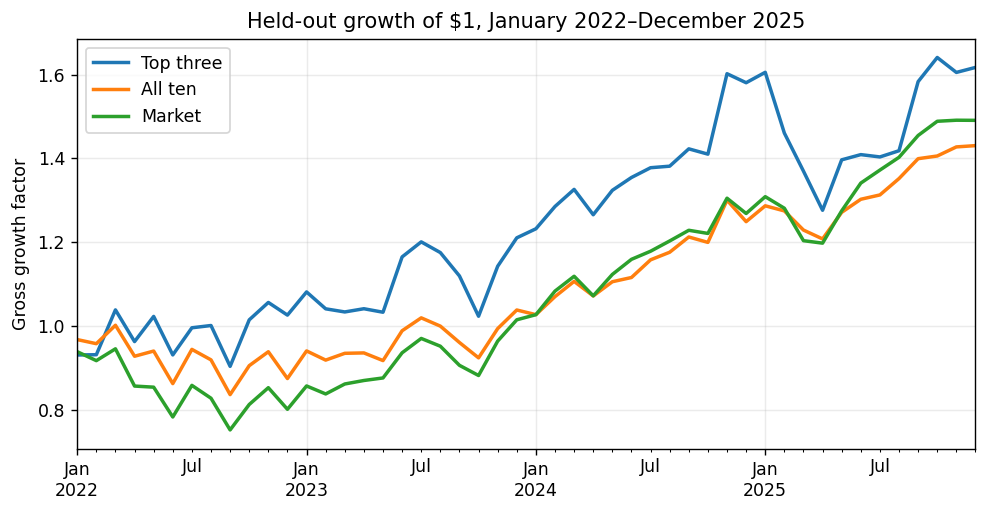

In [6]:
monthly = pd.DataFrame({
    "Top three": by_month[("industry_return", True)],
    "All ten": evaluation.groupby("Month").Industry_Return.mean(),
    "Market": evaluation.groupby("Month").Market_Return.first(),
})
growth = (1 + monthly).cumprod()
summary = pd.DataFrame({"mean monthly": monthly.mean(),
                        "compound 48 months": growth.iloc[-1] - 1})
print(summary.map(lambda v: f"{v:.2%}").to_string())
print(f"Top-three mean monthly excess over market: {(monthly['Top three'] - monthly.Market).mean():+.2%}.")
fig, ax = plt.subplots(figsize=(8, 4.2))
growth.plot(ax=ax, linewidth=2)
ax.set(title="Held-out growth of $1, January 2022–December 2025", ylabel="Gross growth factor", xlabel="")
ax.grid(alpha=.25)
fig.tight_layout()


## Experiment 5 — Number of selected industries

**Question:** How sensitive is the six-month ranking to selecting one, three or five industries? These alternatives are exploratory checks on the held-out sample; the primary rule remains top three.


In [7]:
for k in [1, 3, 5]:
    chosen = select(evaluation, "Mom6", k)
    top = chosen[chosen.Selected]
    rest = chosen[~chosen.Selected]
    print(f"Top {k}: hit {top.Beat.mean():.1%}; others {rest.Beat.mean():.1%}; "
          f"mean selected excess {top.Excess.mean():+.2%} per month.")


Top 1: hit 41.7%; others 47.0%; mean selected excess +0.69% per month.
Top 3: hit 45.8%; others 46.7%; mean selected excess +0.24% per month.
Top 5: hit 47.9%; others 45.0%; mean selected excess +0.21% per month.


## Experiment 6 — Ranking lookback

**Question:** How would three, six and twelve month trailing returns change the top-three result? The six-month horizon was specified before evaluation. The other horizons are exploratory and should not be presented as independently validated strategies.


In [8]:
for lookback in ["Mom3", "Mom6", "Mom12"]:
    chosen = select(evaluation, lookback, 3)
    top = chosen[chosen.Selected]
    print(f"{lookback}: selected hit {top.Beat.mean():.1%}; "
          f"mean selected excess {top.Excess.mean():+.2%} per month.")


Mom3: selected hit 45.1%; mean selected excess +0.08% per month.
Mom6: selected hit 45.8%; mean selected excess +0.24% per month.
Mom12: selected hit 45.8%; mean selected excess +0.23% per month.


## Experiment 7 — Prior market conditions

**Question:** Does the primary selection behave differently after a positive versus a nonpositive prior three-month market return? The condition is known before the next month's industry result, so it does not use the current market return to form the group.


In [9]:
primary["PriorMarketUp"] = primary.MarketMom3 > 0
for state, label in [(True, "Prior market up"), (False, "Prior market flat/down")]:
    subset = primary[primary.PriorMarketUp == state]
    top = subset[subset.Selected]
    other = subset[~subset.Selected]
    n_months = subset.Month.nunique()
    print(f"{label} ({n_months} months): selected hit {top.Beat.mean():.1%}, "
          f"other hit {other.Beat.mean():.1%}, selected mean excess {top.Excess.mean():+.2%}.")


Prior market up (32 months): selected hit 45.8%, other hit 46.0%, selected mean excess +0.24%.
Prior market flat/down (16 months): selected hit 45.8%, other hit 48.2%, selected mean excess +0.25%.


## Experiment 8 — Random-selection reference and uncertainty

**Question:** Is the observed top-three hit rate unusual compared with selecting three industries at random within each month? A fixed-seed simulation draws 20,000 random three-industry baskets from the same 48 months. A separate month-level bootstrap estimates a 95% interval for the primary monthly hit-rate gap. These descriptive intervals do not establish causation or future performance.


In [10]:
hit_grid = evaluation.sort_values(["Month", "Industry_Code"]).Beat.to_numpy().reshape(48, 10)
observed_hit = selected_hit.mean()
rng = np.random.default_rng(2900)
simulated = []
for _ in range(20):
    picks = np.argsort(rng.random((1000, 48, 10)), axis=2)[:, :, :3]
    sampled = np.take_along_axis(hit_grid[None, :, :], picks, axis=2).mean(axis=(1, 2))
    simulated.append(sampled)
simulated = np.concatenate(simulated)
p_one_sided = (1 + (simulated >= observed_hit).sum()) / (1 + len(simulated))
boot = rng.choice(monthly_hit_gap.to_numpy(), size=(20000, 48), replace=True).mean(axis=1)
ci = np.quantile(boot, [.025, .975])
print(f"Observed top-three hit rate {observed_hit:.1%}; random-selection mean {simulated.mean():.1%}.")
print(f"Random-selection one-sided tail fraction: {p_one_sided:.3f} (20,000 draws).")
print(f"Month-bootstrap 95% interval for top-three minus other-seven hit rate: [{ci[0]:+.1%}, {ci[1]:+.1%}].")


Observed top-three hit rate 45.8%; random-selection mean 46.5%.
Random-selection one-sided tail fraction: 0.613 (20,000 draws).
Month-bootstrap 95% interval for top-three minus other-seven hit rate: [-11.9%, +10.1%].


## Experiment 9 — Logistic regression classifier

**Question:** Can lagged industry momentum, lagged volatility and prior market momentum predict whether an industry beats the market? Train only on 2011–2021 and score all 2022–2025 industry-month records. AUC measures ranking and Brier score measures probability error (lower is better); the constant development-rate predictor is a baseline.


In [11]:
predictors = ["Mom1", "Mom3", "Mom6", "Mom12", "Vol6", "MarketMom3"]
X_train, y_train = development[predictors], development.Beat
X_test, y_test = evaluation[predictors], evaluation.Beat
baseline_probability = np.full(len(y_test), y_train.mean())
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=2900))
logit.fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]
print(f"Development hit rate: {y_train.mean():.1%}.")
print(f"Constant baseline: AUC {roc_auc_score(y_test, baseline_probability):.3f}; "
      f"Brier {brier_score_loss(y_test, baseline_probability):.3f}.")
print(f"Logistic regression: AUC {roc_auc_score(y_test, p_logit):.3f}; "
      f"Brier {brier_score_loss(y_test, p_logit):.3f}.")


Development hit rate: 48.3%.
Constant baseline: AUC 0.500; Brier 0.249.
Logistic regression: AUC 0.462; Brier 0.251.


## Experiment 10 — Random forest classifier

**Question:** Does a nonlinear model improve the same held-out predictions? Train the forest on exactly the development rows and predictors used above, then compare its AUC and Brier score with logistic regression. Model results are exploratory; no hyperparameters were tuned on the evaluation set.


In [12]:
forest = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=15, max_features="sqrt", random_state=2900, n_jobs=1
)
forest.fit(X_train, y_train)
p_forest = forest.predict_proba(X_test)[:, 1]
print(f"Random forest: AUC {roc_auc_score(y_test, p_forest):.3f}; "
      f"Brier {brier_score_loss(y_test, p_forest):.3f}.")
print(f"Logistic regression: AUC {roc_auc_score(y_test, p_logit):.3f}; "
      f"Brier {brier_score_loss(y_test, p_logit):.3f}.")
print("Forest feature importance:", ", ".join(
    f"{name} {importance:.2f}" for name, importance in
    sorted(zip(predictors, forest.feature_importances_), key=lambda pair: -pair[1])
))


Random forest: AUC 0.557; Brier 0.247.
Logistic regression: AUC 0.462; Brier 0.251.
Forest feature importance: Vol6 0.19, Mom12 0.17, Mom3 0.17, Mom6 0.17, Mom1 0.17, MarketMom3 0.13


## Findings and limitations

The preselected top-three rule did **not** improve the market beat rate in the 2022–2025 holdout: 45.8% for the selected industries versus 46.7% for the others. The selected group's average monthly return was 1.19% versus 0.95% for the market, but this return comparison answers a different question and can be affected by large individual gains. The month-bootstrap interval for the hit-rate difference ranged from −11.9 to +10.1 percentage points, while the random-selection tail fraction was 0.613. This is weak evidence for a dependable hit-rate advantage.

The logistic classifier scored 0.462 AUC and the random forest scored 0.557 AUC on the same holdout. The forest's improvement over a 0.500 constant baseline is modest. Neither model establishes a reliable future forecasting system.

The primary test is Experiment 3. Experiments 4–8 show what the same historical evaluation period can reveal about returns, sensitivity and uncertainty. Experiments 9–10 compare classifiers trained on earlier observations. A strong in-sample comparison would not guarantee a profitable future system.

The 10 French industry portfolios are a historical proxy rather than the standard sector classifications. This is a small, correlated 48-month evaluation sample. Top-three return comparisons exclude trading costs, taxes and implementation constraints. Additional variants examined on the evaluation period need a new, later holdout before they can be treated as confirmed.

**Sources**

- French, K. R. (n.d.-a). *10 industry portfolios* [Data set]. Kenneth R. French Data Library. Retrieved November 4, 2026, from https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/10_Industry_Portfolios_CSV.zip
- French, K. R. (n.d.-b). *Fama/French 3 factors* [Data set]. Kenneth R. French Data Library. Retrieved November 4, 2026, from https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip
